# Практична робота № 4
## Підготовка даних, Pipeline і логістична регресія

**Дисципліна:** Розпізнавання образів та класичне машинне навчання

**Виконав:** Маслак Олександр Ростиславович

**Група:** ІН-42/1

**Дата виконання:** 18.11.2026

## 1. Мета роботи

Навчитися правильно розділяти дані, будувати конвеєр попередньої обробки без витоку інформації та досліджувати логістичну регресію за допомогою крос-валідації.

## Постановка задачі

Об'єктом дослідження є набір даних Heart Disease, що містить характеристики пацієнтів.

Мета класифікації — визначити наявність або відсутність ознак серцевого захворювання за вхідними характеристиками.

Використовується бінарна класифікація:
- 0 — відсутність ознак захворювання;
- 1 — наявність ознак захворювання.

Позитивним класом є клас 1.

Для класифікації використовуються 13 вхідних ознак і цільова змінна target.

Основною метрикою оцінювання обрано F1-score.

## 10. Завантаження та первинна перевірка даних

In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("heart.csv")

print("Перші рядки набору даних:")
display(df.head())

print("Розмір набору даних:")
print(df.shape)

print("Типи даних:")
print(df.dtypes)

print("Пропущені значення:")
print(df.isnull().sum())

Saving heart.csv to heart.csv
Перші рядки набору даних:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Розмір набору даних:
(303, 14)
Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object
Пропущені значення:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [2]:
print("Розподіл класів:")
print(df["target"].value_counts())

print("\nКількість кожного класу у відсотках:")
print(df["target"].value_counts(normalize=True) * 100)

print("\nУнікальні значення цільової змінної:")
print(df["target"].unique())

Розподіл класів:
target
1    165
0    138
Name: count, dtype: int64

Кількість кожного класу у відсотках:
target
1    54.455446
0    45.544554
Name: proportion, dtype: float64

Унікальні значення цільової змінної:
[1 0]


## 11. Визначення числових і категоріальних ознак

In [3]:
numerical_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]

categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

target = "target"

print("Числові ознаки:")
print(numerical_features)

print("\nКатегоріальні ознаки:")
print(categorical_features)

print("\nЦільова змінна:")
print(target)

print("\nПеревірка наявності всіх стовпців:")
print(set(numerical_features + categorical_features + [target]).issubset(df.columns))

Числові ознаки:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Категоріальні ознаки:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Цільова змінна:
target

Перевірка наявності всіх стовпців:
True


In [4]:
from sklearn.model_selection import train_test_split

X = df[numerical_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nРозподіл класів у навчальній вибірці:")
print(y_train.value_counts())

print("\nРозподіл класів у тестовій вибірці:")
print(y_test.value_counts())

Розмір навчальної вибірки: (242, 13)
Розмір тестової вибірки: (61, 13)

Розподіл класів у навчальній вибірці:
target
1    132
0    110
Name: count, dtype: int64

Розподіл класів у тестовій вибірці:
target
1    33
0    28
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Створено 5-кратну стратифіковану крос-валідацію.")

Створено 5-кратну стратифіковану крос-валідацію.


## 12. Створення Pipeline попередньої обробки даних

Для числових ознак буде використано заповнення пропущених значень медіаною та стандартизацію. Для категоріальних ознак — заповнення найчастішим значенням і кодування One-Hot Encoding.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Pipeline попередньої обробки даних створено.")

Pipeline попередньої обробки даних створено.


In [9]:
from sklearn.linear_model import LogisticRegression

In [10]:
numeric_pipeline_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_unscaled = ColumnTransformer([
    ("num", numeric_pipeline_unscaled, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

model_unscaled = Pipeline([
    ("preprocessor", preprocessor_unscaled),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Pipeline логістичної регресії без стандартизації створено.")

Pipeline логістичної регресії без стандартизації створено.


In [11]:
model_scaled = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("Pipeline логістичної регресії зі стандартизацією створено.")

Pipeline логістичної регресії зі стандартизацією створено.


Основною метрикою для порівняння моделей обрано F1-score. Вона враховує точність (precision) і повноту (recall) та дає змогу оцінити якість класифікації позитивного класу 1.

In [12]:
from sklearn.model_selection import cross_validate

scoring = ["f1", "roc_auc"]

results_unscaled = cross_validate(
    model_unscaled,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

results_scaled = cross_validate(
    model_scaled,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Результати крос-валідації отримано.")

Результати крос-валідації отримано.


In [13]:
comparison = pd.DataFrame({
    "Модель": ["Без стандартизации", "Со стандартизацией"],
    "F1-score": [
        results_unscaled["test_f1"].mean(),
        results_scaled["test_f1"].mean()
    ],
    "F1-score std": [
        results_unscaled["test_f1"].std(),
        results_scaled["test_f1"].std()
    ],
    "ROC AUC": [
        results_unscaled["test_roc_auc"].mean(),
        results_scaled["test_roc_auc"].mean()
    ],
    "ROC AUC std": [
        results_unscaled["test_roc_auc"].std(),
        results_scaled["test_roc_auc"].std()
    ]
})

display(comparison.round(4))


,Модель,F1-score,F1-score std,ROC AUC,ROC AUC std
0,Без стандартизации,0.8286,0.0600,0.8904,0.0363
1,Со стандартизацией,0.8336,0.0511,0.8904,0.0355


In [14]:
results_unscaled = cross_validate(
    model_unscaled,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_estimator=True
)

results_scaled = cross_validate(
    model_scaled,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_estimator=True
)

iterations_unscaled = [
    estimator.named_steps["classifier"].n_iter_[0]
    for estimator in results_unscaled["estimator"]
]

iterations_scaled = [
    estimator.named_steps["classifier"].n_iter_[0]
    for estimator in results_scaled["estimator"]
]

print("Кількість ітерацій без стандартизації:", iterations_unscaled)
print("Кількість ітерацій зі стандартизацією:", iterations_scaled)

Кількість ітерацій без стандартизації: [np.int32(981), np.int32(1250), np.int32(1307), np.int32(1334), np.int32(1154)]
Кількість ітерацій зі стандартизацією: [np.int32(15), np.int32(20), np.int32(21), np.int32(19), np.int32(19)]


## 13. Дослідження регуляризації L1 і L2

Для дослідження регуляризації буде використано методи L1 і L2 та значення параметра C: 0.01, 0.1, 1, 10 і 100. Найкращу конфігурацію буде обрано за результатами крос-валідації на навчальній вибірці.

In [15]:
from sklearn.model_selection import cross_validate

C_values = [0.01, 0.1, 1, 10, 100]
penalties = ["l1", "l2"]

regularization_results = []

for penalty in penalties:
    for C in C_values:
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(
                penalty=penalty,
                C=C,
                solver="liblinear",
                max_iter=2000
            ))
        ])

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=["f1", "roc_auc"]
        )

        regularization_results.append({
            "Регуляризация": penalty.upper(),
            "C": C,
            "F1-score": scores["test_f1"].mean(),
            "F1-score std": scores["test_f1"].std(),
            "ROC AUC": scores["test_roc_auc"].mean(),
            "ROC AUC std": scores["test_roc_auc"].std()
        })

regularization_df = pd.DataFrame(regularization_results)

display(regularization_df.round(4))

,Регуляризация,C,F1-score,F1-score std,ROC AUC,ROC AUC std
0,L1,0.01,0.0000,0.0000,0.5000,0.0000
1,L1,0.10,0.8437,0.0710,0.8684,0.0767
2,L1,1.00,0.8417,0.0489,0.8931,0.0389
3,L1,10.00,0.8220,0.0574,0.8850,0.0309
4,L1,100.00,0.8220,0.0574,0.8836,0.0316
5,L2,0.01,0.8391,0.0702,0.8940,0.0615
6,L2,0.10,0.8421,0.0610,0.8960,0.0518
7,L2,1.00,0.8336,0.0511,0.8917,0.0358
8,L2,10.00,0.8191,0.0620,0.8836,0.0318
9,L2,100.00,0.8220,0.0574,0.8840,0.0317


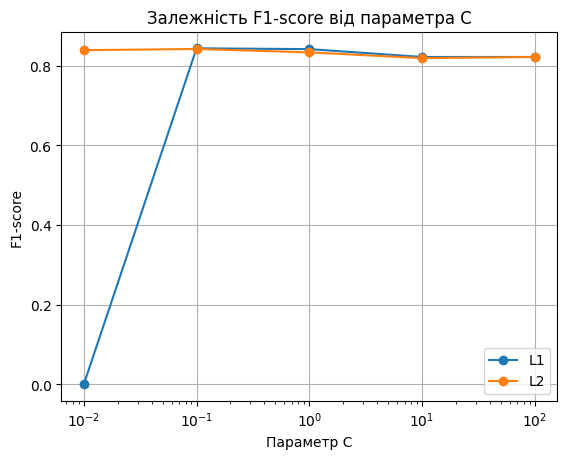

In [16]:
import matplotlib.pyplot as plt

for penalty in penalties:
    subset = regularization_df[
        regularization_df["Регуляризация"] == penalty.upper()
    ]

    plt.plot(
        subset["C"],
        subset["F1-score"],
        marker="o",
        label=penalty.upper()
    )

plt.xscale("log")
plt.xlabel("Параметр C")
plt.ylabel("F1-score")
plt.title("Залежність F1-score від параметра C")
plt.legend()
plt.grid()
plt.show()

In [17]:
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        penalty="l1",
        C=0.1,
        solver="liblinear",
        max_iter=2000
    ))
])

best_model.fit(X_train, y_train)

print("Найкращу модель навчено.")

Найкращу модель навчено.


In [18]:
feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = best_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefficients,
    "Абсолютне значення": abs(coefficients)
})

top_coefficients = coef_df.sort_values(
    by="Абсолютне значення",
    ascending=False
).head(5)

display(top_coefficients.round(4))

,Ознака,Коефіцієнт,Абсолютне значення
7,cat__cp_0,-0.8702,0.8702
28,cat__thal_2,0.7841,0.7841
21,cat__ca_0,0.4865,0.4865
4,num__oldpeak,-0.4620,0.4620
3,num__thalach,0.2729,0.2729


Коефіцієнти логістичної регресії показують напрямок і силу зв'язку ознак із позитивним класом. Додатні коефіцієнти збільшують логарифм шансів належності до класу 1, а від'ємні — зменшують. Найбільші за абсолютним значенням коефіцієнти отримали ознаки cp_0, thal_2, ca_0, oldpeak і thalach. Коефіцієнти моделі не доводять причинно-наслідковий зв'язок.

## 14. Висновок

Під час практичної роботи було виконано підготовку даних, створено Pipeline попередньої обробки та досліджено логістичну регресію.

Було встановлено, що стандартизація числових ознак покращує результат F1-score з 0.8286 до 0.8336 та значно прискорює збіжність моделі.

Під час дослідження регуляризації найкращий результат за основною метрикою F1-score отримано для L1-регуляризації з параметром C = 0.1. Значення F1-score становило 0.8437.

Також було визначено п'ять ознак із найбільшими абсолютними значеннями коефіцієнтів та проаналізовано їхній вплив на прогноз моделі.

Отже, стандартизація та правильний вибір регуляризації мають важливе значення для якості й ефективності логістичної регресії.

# Практична робота № 5
## Порівняння моделей k-NN, GaussianNB, LDA та QDA

## 1. Порівняння k-NN зі стандартизацією та без неї

Для оцінювання моделі k-NN перевіряються значення кількості сусідів k = 3, 5, 7, 9, 11, 15. Порівняння моделей виконується за допомогою п'ятикратної стратифікованої крос-валідації. Основною метрикою є F1-score.

In [19]:
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

k_values = [3, 5, 7, 9, 11, 15]

knn_results = []

for scale_name, base_model in [
    ("Без стандартизації", model_unscaled),
    ("Зі стандартизацією", model_scaled)
]:
    for k in k_values:
        knn_model = clone(base_model)
        knn_model.set_params(classifier=KNeighborsClassifier(n_neighbors=k))

        scores = cross_validate(
            knn_model,
            X_train,
            y_train,
            cv=cv,
            scoring="f1",
            return_train_score=False
        )

        knn_results.append({
            "Стандартизація": scale_name,
            "k": k,
            "Середній F1": scores["test_score"].mean(),
            "Стандартне відхилення": scores["test_score"].std()
        })

knn_results_df = pd.DataFrame(knn_results)

print("Порівняння моделей k-NN:")
display(knn_results_df.round(4))

Порівняння моделей k-NN:


,Стандартизація,k,Середній F1,Стандартне відхилення
0,Без стандартизації,3,0.6786,0.0184
1,Без стандартизації,5,0.6994,0.0235
2,Без стандартизації,7,0.6865,0.0480
3,Без стандартизації,9,0.6935,0.0561
4,Без стандартизації,11,0.6766,0.0567
5,Без стандартизації,15,0.6752,0.0762
6,Зі стандартизацією,3,0.8275,0.0531
7,Зі стандартизацією,5,0.8528,0.0365
8,Зі стандартизацією,7,0.8401,0.0410
9,Зі стандартизацією,9,0.8402,0.0537


### 1.1. Аналіз впливу стандартизації

Результати показали, що стандартизація числових ознак значно покращує роботу алгоритму k-NN. Найкращий результат для обох варіантів отримано при k = 5. Без стандартизації середній F1-score становить 0.6994, а зі стандартизацією — 0.8528. Тому для подальших експериментів використовується стандартизована модель.

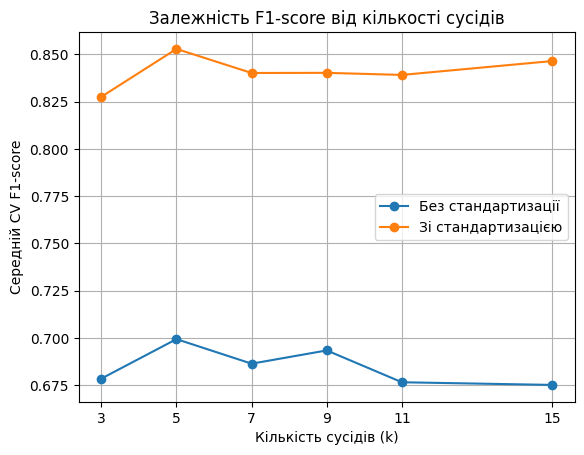

In [20]:
import matplotlib.pyplot as plt

for scale_name in knn_results_df["Стандартизація"].unique():
    data = knn_results_df[knn_results_df["Стандартизація"] == scale_name]

    plt.plot(
        data["k"],
        data["Середній F1"],
        marker="o",
        label=scale_name
    )

plt.xlabel("Кількість сусідів (k)")
plt.ylabel("Середній CV F1-score")
plt.title("Залежність F1-score від кількості сусідів")
plt.xticks(k_values)
plt.legend()
plt.grid()
plt.show()

## 2. Порівняння метрик відстані для k-NN

Для найкращого значення k = 5 порівнюються евклідова та мангеттенська метрики відстані. Експеримент проводиться зі стандартизацією ознак за допомогою однакової п'ятикратної стратифікованої крос-валідації.

In [21]:
distance_results = []

for distance_name in ["euclidean", "manhattan"]:
    knn_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            metric=distance_name
        ))
    ])

    scores = cross_validate(
        knn_model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1"
    )

    distance_results.append({
        "Метрика відстані": distance_name,
        "Середній F1": scores["test_score"].mean(),
        "Стандартне відхилення": scores["test_score"].std()
    })

distance_results_df = pd.DataFrame(distance_results)

print("Порівняння метрик відстані:")
display(distance_results_df.round(4))

Порівняння метрик відстані:


,Метрика відстані,Середній F1,Стандартне відхилення
0,euclidean,0.8528,0.0365
1,manhattan,0.8418,0.0484


### 2.1. Висновок щодо метрик відстані

За результатами крос-валідації евклідова метрика відстані показала кращий результат, ніж мангеттенська. Середній F1-score для евклідової метрики становить 0.8528, а для мангеттенської — 0.8418. Тому для подальшого порівняння обрано евклідову метрику.

## 3. Порівняння ймовірнісних моделей

У цьому розділі досліджуються три ймовірнісні моделі класифікації: Gaussian Naive Bayes, Linear Discriminant Analysis та Quadratic Discriminant Analysis. Усі моделі використовують однакову попередню обробку даних і п'ятикратну стратифіковану крос-валідацію.

In [22]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

probabilistic_models = {
    "GaussianNB": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis()
}

probabilistic_results = []

for model_name, classifier in probabilistic_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        return_train_score=False
    )

    probabilistic_results.append({
        "Модель": model_name,
        "Середній F1": scores["test_f1"].mean(),
        "Стандартне відхилення F1": scores["test_f1"].std(),
        "Середній ROC AUC": scores["test_roc_auc"].mean(),
        "Стандартне відхилення ROC AUC": scores["test_roc_auc"].std()
    })

probabilistic_results_df = pd.DataFrame(probabilistic_results)

print("Порівняння ймовірнісних моделей:")
display(probabilistic_results_df.round(4))

Порівняння ймовірнісних моделей:


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

,Модель,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Стандартне відхилення ROC AUC
0,GaussianNB,0.7318,0.0749,0.8608,0.0686
1,LDA,0.8527,0.0587,0.8900,0.0399
2,QDA,0.4350,0.1936,0.7733,0.0467


### 3.1. Дослідження стабільності QDA

Для перевірки стабільності моделі QDA досліджуються значення параметра регуляризації reg_param: 0, 0.01 та 0.1. Це дає змогу оцінити вплив регуляризації на коваріаційні матриці та якість класифікації.

In [23]:
qda_results = []

for reg in [0, 0.01, 0.1]:
    qda_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", QuadraticDiscriminantAnalysis(reg_param=reg))
    ])

    scores = cross_validate(
        qda_model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        }
    )

    qda_results.append({
        "reg_param": reg,
        "Середній F1": scores["test_f1"].mean(),
        "Стандартне відхилення F1": scores["test_f1"].std(),
        "Середній ROC AUC": scores["test_roc_auc"].mean(),
        "Стандартне відхилення ROC AUC": scores["test_roc_auc"].std()
    })

qda_results_df = pd.DataFrame(qda_results)

print("Перевірка стабільності QDA:")
display(qda_results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

Перевірка стабільності QDA:


,reg_param,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Стандартне відхилення ROC AUC
0,0.00,0.4350,0.1936,0.7733,0.0467
1,0.01,0.7900,0.1043,0.8369,0.0795
2,0.10,0.8432,0.0848,0.8804,0.0573


### 3.2. Аналіз розподілу числових ознак для GaussianNB

Для аналізу припущення про розподіл ознак у моделі GaussianNB розглядаються три числові ознаки: вік (age), рівень холестерину (chol) та максимальна частота серцевих скорочень (thalach). Розподіли порівнюються окремо для кожного класу цільової змінної.

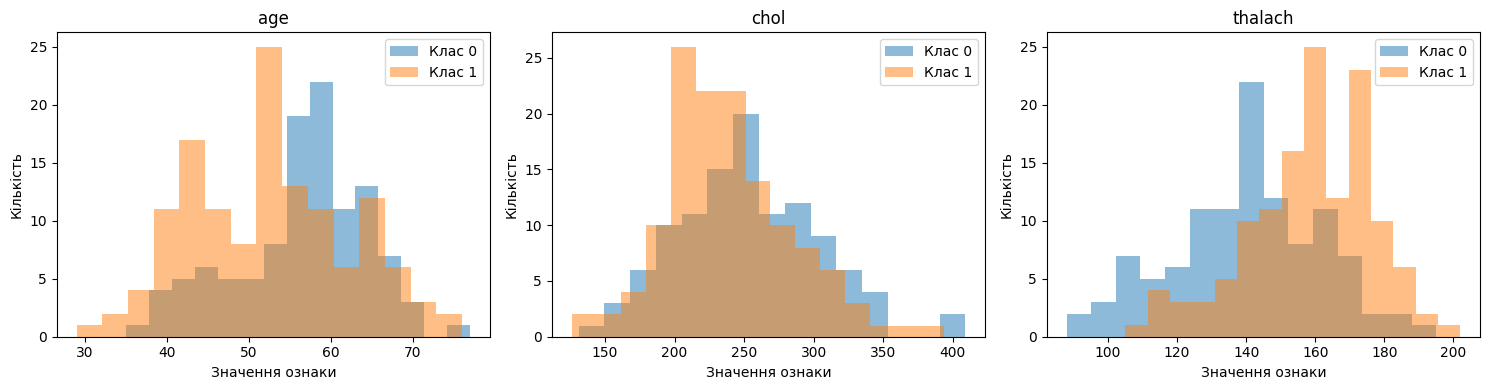

In [24]:
analysis_data = X_train[["age", "chol", "thalach"]].copy()
analysis_data["target"] = y_train

features = ["age", "chol", "thalach"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    for class_value in [0, 1]:
        values = analysis_data[analysis_data["target"] == class_value][feature]

        axes[i].hist(
            values,
            bins=15,
            alpha=0.5,
            label=f"Клас {class_value}"
        )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Значення ознаки")
    axes[i].set_ylabel("Кількість")
    axes[i].legend()

plt.tight_layout()
plt.show()

## 4. Отримання позавибіркових імовірностей

За допомогою cross_val_predict отримуються позавибіркові ймовірності належності об'єктів навчальної вибірки до позитивного класу. Для цього використовуються моделі GaussianNB, LDA та QDA з однаковою п'ятикратною стратифікованою крос-валідацією.

In [25]:
from sklearn.model_selection import cross_val_predict

oof_models = {
    "GaussianNB": GaussianNB(),
    "LDA": LinearDiscriminantAnalysis(),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.1)
}

oof_data = pd.DataFrame({
    "Індекс об'єкта": X_train.index[:5],
    "Справжній клас": y_train.iloc[:5].values
})

for model_name, classifier in oof_models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba"
    )

    oof_data[f"Ймовірність класу 1 ({model_name})"] = probabilities[:5, 1]

print("Позавибіркові ймовірності для перших п'яти об'єктів:")
display(oof_data.round(4))

Позавибіркові ймовірності для перших п'яти об'єктів:


,Індекс об'єкта,Справжній клас,Ймовірність класу 1 (GaussianNB),Ймовірність класу 1 (LDA),Ймовірність класу 1 (QDA)
0,19,1,0.9831,0.9965,0.9477
1,247,0,0.0000,0.2969,0.1249
2,289,0,0.0000,0.0040,0.0020
3,288,0,0.0000,0.0014,0.0005
4,60,1,0.8890,0.9841,0.9953


### 4.1. Аналіз отриманих імовірностей

Отримані результати показують, що моделі оцінюють імовірність належності об'єктів до позитивного класу по-різному. Для об'єктів із класом 1 моделі переважно визначили високу ймовірність позитивного класу, а для об'єктів із класом 0 — низьку. Найбільші відмінності між моделями спостерігаються для об'єкта з індексом 247.

## 5. Загальне порівняння моделей

На цьому етапі порівнюються найкраща модель k-NN та ймовірнісні моделі GaussianNB, LDA і QDA. Для QDA використовується параметр регуляризації reg_param = 0.1. Оцінювання проводиться за допомогою однакової п'ятикратної стратифікованої крос-валідації. Основними метриками є F1-score та ROC AUC.

In [26]:
comparison_models = {
    "k-NN (k=5, euclidean)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            metric="euclidean"
        ))
    ]),
    "GaussianNB": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ]),
    "LDA": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearDiscriminantAnalysis())
    ]),
    "QDA (reg_param=0.1)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", QuadraticDiscriminantAnalysis(reg_param=0.1))
    ])
}

comparison_results = []

for model_name, model in comparison_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        return_train_score=False
    )

    comparison_results.append({
        "Модель": model_name,
        "Середній F1": scores["test_f1"].mean(),
        "Стандартне відхилення F1": scores["test_f1"].std(),
        "Середній ROC AUC": scores["test_roc_auc"].mean(),
        "Стандартне відхилення ROC AUC": scores["test_roc_auc"].std()
    })

comparison_results_df = pd.DataFrame(comparison_results)

print("Загальне порівняння моделей:")
display(comparison_results_df.round(4))

Загальне порівняння моделей:


,Модель,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Стандартне відхилення ROC AUC
0,"k-NN (k=5, euclidean)",0.8528,0.0365,0.8861,0.0446
1,GaussianNB,0.7318,0.0749,0.8608,0.0686
2,LDA,0.8527,0.0587,0.8900,0.0399
3,QDA (reg_param=0.1),0.8432,0.0848,0.8804,0.0573


## 6. Висновок

У ході практичної роботи було проведено порівняння моделей k-NN, GaussianNB, LDA та QDA за допомогою п'ятикратної стратифікованої крос-валідації.

Було встановлено, що стандартизація числових ознак значно покращує результати k-NN. Найкраще значення кількості сусідів — k = 5, а найкращою метрикою відстані виявилася евклідова.

Серед ймовірнісних моделей найкращі результати показала LDA з F1-score 0.8527 та ROC AUC 0.8900. Для QDA було виявлено проблему з коваріаційними матрицями. Використання регуляризації reg_param = 0.1 покращило F1-score моделі до 0.8432.

У загальному порівнянні найкращий F1-score отримала модель k-NN (0.8528), а найкращий ROC AUC — LDA (0.8900). Також було отримано позавибіркові ймовірності для окремих об'єктів навчальної вибірки.

Усі експерименти виконувалися на навчальній вибірці з використанням однакового розбиття та крос-валідації. Тестова вибірка не використовувалася для підбору моделей.

# Практична робота № 6
## Порівняння лінійної та RBF-моделей SVM

## 1. Лінійна модель SVM

Для побудови лінійної моделі SVM використовується масштабування числових ознак. Параметр C визначає компроміс між шириною розділювальної смуги та штрафом за помилки класифікації. Перевіряються значення C = 0.1, 1 та 10 за допомогою п'ятикратної стратифікованої крос-валідації.

In [27]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

linear_results = []

for c_value in [0.1, 1, 10]:
    svm_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear", C=c_value))
    ])

    scores = cross_validate(
        svm_model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        return_train_score=False
    )

    linear_results.append({
        "C": c_value,
        "Середній F1": scores["test_f1"].mean(),
        "Стандартне відхилення F1": scores["test_f1"].std(),
        "Середній ROC AUC": scores["test_roc_auc"].mean(),
        "Середній час навчання": scores["fit_time"].mean()
    })

linear_results_df = pd.DataFrame(linear_results)

print("Результати лінійної SVM:")
display(linear_results_df.round(4))

Результати лінійної SVM:


,C,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Середній час навчання
0,0.1,0.8406,0.0544,0.8896,0.0948
1,1.0,0.8155,0.0590,0.8910,0.1777
2,10.0,0.8222,0.0534,0.8877,0.1585


## 2. SVM із RBF-ядром

RBF-ядро дає змогу моделі будувати нелінійні межі класифікації. Параметр C контролює штраф за помилки класифікації, а gamma визначає локальність впливу окремих навчальних об'єктів. Мале значення gamma формує плавнішу межу, а надто велике може призвести до перенавчання.

In [28]:
rbf_results = []

for c_value in [0.1, 1, 10]:
    for gamma_value in ["scale", 0.01, 0.1]:
        svm_model = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", SVC(
                kernel="rbf",
                C=c_value,
                gamma=gamma_value
            ))
        ])

        scores = cross_validate(
            svm_model,
            X_train,
            y_train,
            cv=cv,
            scoring={
                "f1": "f1",
                "roc_auc": "roc_auc"
            },
            return_train_score=False
        )

        rbf_results.append({
            "C": c_value,
            "Gamma": gamma_value,
            "Середній F1": scores["test_f1"].mean(),
            "Стандартне відхилення F1": scores["test_f1"].std(),
            "Середній ROC AUC": scores["test_roc_auc"].mean(),
            "Середній час навчання": scores["fit_time"].mean()
        })

rbf_results_df = pd.DataFrame(rbf_results)

print("Результати SVM з RBF-ядром:")
display(
    rbf_results_df.sort_values(
        by="Середній F1",
        ascending=False
    ).round(4)
)

Результати SVM з RBF-ядром:


,C,Gamma,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Середній час навчання
2,0.1,0.1,0.8491,0.0631,0.8900,0.0967
4,1.0,0.01,0.8491,0.0593,0.8928,0.0306
0,0.1,scale,0.8449,0.0610,0.8900,0.1871
7,10.0,0.01,0.8433,0.0559,0.8865,0.0351
3,1.0,scale,0.8383,0.0467,0.8886,0.0886
5,1.0,0.1,0.8335,0.0554,0.8879,0.0285
8,10.0,0.1,0.8143,0.0668,0.8521,0.0396
6,10.0,scale,0.8110,0.0671,0.8507,0.0456
1,0.1,0.01,0.7358,0.0206,0.8898,0.1341


## 3. Пошук найкращих параметрів за допомогою GridSearchCV

Для автоматичного підбору гіперпараметрів використовується GridSearchCV. Перевіряються лінійне та RBF-ядро. Для лінійного ядра параметр gamma не задається. Основною метрикою для пошуку є F1-score.

In [29]:
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкращий середній CV F1-score:")
print(round(grid_search.best_score_, 4))

Найкращі параметри:
{'classifier__C': 0.1, 'classifier__gamma': 0.1, 'classifier__kernel': 'rbf'}

Найкращий середній CV F1-score:
0.8491


### 3.1. Найкращі конфігурації SVM

Виводяться п'ять найкращих конфігурацій за середнім значенням F1-score, отриманим під час крос-валідації.

In [30]:
grid_results_df = pd.DataFrame(grid_search.cv_results_)

top_configs = grid_results_df.sort_values(
    by="mean_test_score",
    ascending=False
).head(5)

top_configs = top_configs[[
    "param_classifier__kernel",
    "param_classifier__C",
    "param_classifier__gamma",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time"
]]

top_configs.columns = [
    "Ядро",
    "C",
    "Gamma",
    "Середній F1",
    "Стандартне відхилення F1",
    "Середній час навчання"
]

print("П'ять найкращих конфігурацій SVM:")
display(top_configs.round(4))

П'ять найкращих конфігурацій SVM:


,Ядро,C,Gamma,Середній F1,Стандартне відхилення F1,Середній час навчання
5,rbf,0.1,0.1,0.8491,0.0631,0.0488
7,rbf,1.0,0.01,0.8491,0.0593,0.0751
3,rbf,0.1,scale,0.8449,0.0610,0.1584
10,rbf,10.0,0.01,0.8433,0.0559,0.0347
0,linear,0.1,NaN,0.8406,0.0544,0.0655


## 4. Порівняння лінійної та RBF-моделей SVM

Порівнюються найкращі конфігурації лінійної та RBF-моделей за середнім F1-score, ROC AUC, стандартним відхиленням F1-score та часом навчання. Для кожної моделі використовуються результати однакової крос-валідації.

In [31]:
best_linear = linear_results_df.loc[
    linear_results_df["Середній F1"].idxmax()
]

best_rbf = rbf_results_df.loc[
    rbf_results_df["Середній F1"].idxmax()
]

svm_comparison_df = pd.DataFrame([
    {
        "Модель": f"Linear SVM (C={best_linear['C']})",
        "Середній F1": best_linear["Середній F1"],
        "Стандартне відхилення F1": best_linear["Стандартне відхилення F1"],
        "Середній ROC AUC": best_linear["Середній ROC AUC"],
        "Середній час навчання": best_linear["Середній час навчання"]
    },
    {
        "Модель": f"RBF SVM (C={best_rbf['C']}, gamma={best_rbf['Gamma']})",
        "Середній F1": best_rbf["Середній F1"],
        "Стандартне відхилення F1": best_rbf["Стандартне відхилення F1"],
        "Середній ROC AUC": best_rbf["Середній ROC AUC"],
        "Середній час навчання": best_rbf["Середній час навчання"]
    }
])

print("Порівняння найкращих моделей SVM:")
display(svm_comparison_df.round(4))

Порівняння найкращих моделей SVM:


,Модель,Середній F1,Стандартне відхилення F1,Середній ROC AUC,Середній час навчання
0,Linear SVM (C=0.1),0.8406,0.0544,0.8896,0.0948
1,"RBF SVM (C=0.1, gamma=0.1)",0.8491,0.0631,0.8900,0.0967


## 5. Висновок

У ході практичної роботи було досліджено лінійну SVM та SVM із RBF-ядром. Для підбору параметрів використовувалася п'ятикратна стратифікована крос-валідація та GridSearchCV.

Найкращий результат показала модель RBF SVM з параметрами C = 0.1 та gamma = 0.1. Її середній F1-score становить 0.8491, а ROC AUC — 0.8900.

Параметр C впливає на штраф за помилки класифікації, а gamma визначає вплив окремих навчальних об'єктів у RBF-ядрі. Надто великі значення цих параметрів можуть призвести до перенавчання.

RBF-модель показала дещо кращі значення F1-score та ROC AUC порівняно з лінійною моделлю. Тому для подальшого порівняння обирається RBF SVM.

# Практична робота № 7
## Фінальне порівняння моделей класифікації

## 1. Крос-валідаційні ROC-криві моделей

Для порівняння моделей будуються ROC-криві на основі позавибіркових прогнозів навчальної вибірки. Для моделей із predict_proba використовуються ймовірності позитивного класу, а для SVM — decision_function. Усі моделі оцінюються за однаковою п'ятикратною стратифікованою крос-валідацією.

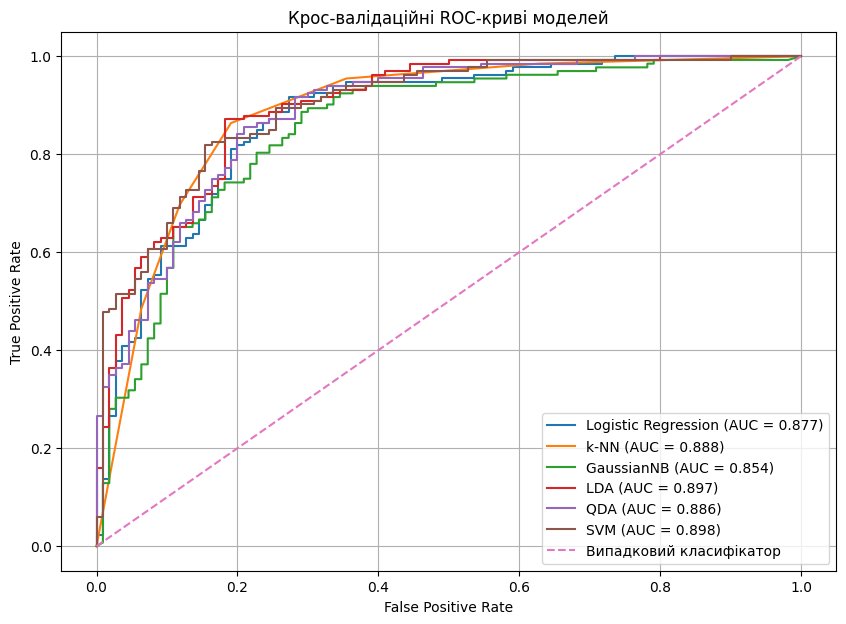

Порівняння моделей за CV ROC AUC:


,Модель,CV ROC AUC
0,Logistic Regression,0.8766
1,k-NN,0.8875
2,GaussianNB,0.8544
3,LDA,0.8971
4,QDA,0.8862
5,SVM,0.8978


In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

roc_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            penalty="l1",
            C=0.1,
            solver="liblinear",
            max_iter=1000
        ))
    ]),
    "k-NN": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5,
            metric="euclidean"
        ))
    ]),
    "GaussianNB": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ]),
    "LDA": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LinearDiscriminantAnalysis())
    ]),
    "QDA": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", QuadraticDiscriminantAnalysis(
            reg_param=0.1
        ))
    ]),
    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            kernel="rbf",
            C=0.1,
            gamma=0.1
        ))
    ])
}

plt.figure(figsize=(10, 7))

roc_auc_results = []

for name, model in roc_models.items():
    if name == "SVM":
        predictions = cross_val_predict(
            model,
            X_train,
            y_train,
            cv=cv,
            method="decision_function"
        )
    else:
        predictions = cross_val_predict(
            model,
            X_train,
            y_train,
            cv=cv,
            method="predict_proba"
        )[:, 1]

    fpr, tpr, thresholds = roc_curve(y_train, predictions)
    auc_value = roc_auc_score(y_train, predictions)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

    roc_auc_results.append({
        "Модель": name,
        "CV ROC AUC": auc_value
    })

plt.plot([0, 1], [0, 1], linestyle="--", label="Випадковий класифікатор")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Крос-валідаційні ROC-криві моделей")
plt.legend()
plt.grid()
plt.show()

roc_auc_df = pd.DataFrame(roc_auc_results)

print("Порівняння моделей за CV ROC AUC:")
display(roc_auc_df.round(4))

## 2. Матриці помилок моделей

Для найкращої логістичної регресії, k-NN, LDA та SVM будуються матриці помилок на основі позавибіркових прогнозів навчальної вибірки. Це дає змогу оцінити правильні прогнози, хибнопозитивні та хибнонегативні результати.

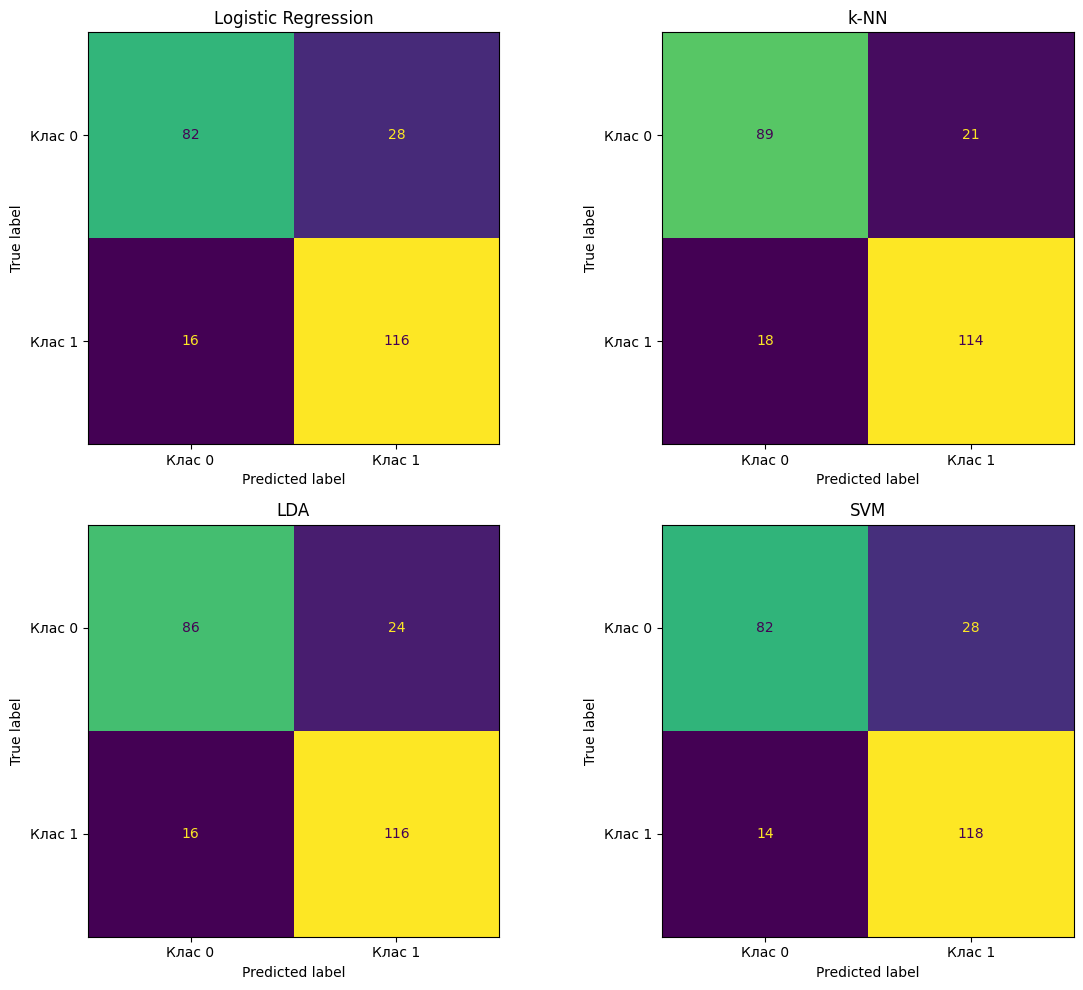

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion_models = {
    "Logistic Regression": roc_models["Logistic Regression"],
    "k-NN": roc_models["k-NN"],
    "LDA": roc_models["LDA"],
    "SVM": roc_models["SVM"]
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for (name, model), ax in zip(confusion_models.items(), axes.ravel()):
    predictions = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv
    )

    cm = confusion_matrix(y_train, predictions)

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Клас 0", "Клас 1"]
    )

    display_matrix.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 3. Підсумкове порівняння моделей

Формується єдина таблиця порівняння моделей за результатами крос-валідації. Для оцінювання використовуються F1-score, Recall, ROC AUC, стандартне відхилення F1-score та час навчання.

In [34]:
comparison_results = []

model_parameters = {
    "Logistic Regression": "L1, C=0.1",
    "k-NN": "k=5, Euclidean",
    "GaussianNB": "Стандартні параметри",
    "LDA": "Стандартні параметри",
    "QDA": "reg_param=0.1",
    "SVM": "RBF, C=0.1, gamma=0.1"
}

for name, model in roc_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        return_train_score=False
    )

    comparison_results.append({
        "Модель": name,
        "Параметри": model_parameters[name],
        "CV F1": scores["test_f1"].mean(),
        "CV F1 std": scores["test_f1"].std(),
        "CV Recall": scores["test_recall"].mean(),
        "CV ROC AUC": scores["test_roc_auc"].mean(),
        "Час навчання": scores["fit_time"].mean()
    })

cv_comparison_df = pd.DataFrame(comparison_results)

cv_comparison_df = cv_comparison_df.sort_values(
    by="CV F1",
    ascending=False
).reset_index(drop=True)

print("Підсумкова таблиця порівняння моделей:")
display(cv_comparison_df.round(4))

Підсумкова таблиця порівняння моделей:


,Модель,Параметри,CV F1,CV F1 std,CV Recall,CV ROC AUC,Час навчання
0,k-NN,"k=5, Euclidean",0.8528,0.0365,0.8635,0.8861,0.0315
1,LDA,Стандартні параметри,0.8527,0.0587,0.8781,0.8900,0.0335
2,SVM,"RBF, C=0.1, gamma=0.1",0.8491,0.0631,0.8937,0.8900,0.0401
3,Logistic Regression,"L1, C=0.1",0.8437,0.0710,0.8786,0.8684,0.0368
4,QDA,reg_param=0.1,0.8432,0.0848,0.8558,0.8804,0.0311
5,GaussianNB,Стандартні параметри,0.7318,0.0749,0.6368,0.8608,0.0302


### 3.1. Збереження таблиці порівняння

Підсумкова таблиця результатів крос-валідації зберігається у форматі CSV.

In [35]:
import os

os.makedirs("reports", exist_ok=True)

cv_comparison_df.to_csv(
    "reports/cv_model_comparison.csv",
    index=False
)

print("Таблицю збережено у reports/cv_model_comparison.csv")

Таблицю збережено у reports/cv_model_comparison.csv


## 4. Вибір фінальної моделі

Для фінального оцінювання обрано модель Linear Discriminant Analysis (LDA). За результатами крос-валідації її F1-score становить 0.8527, що майже не відрізняється від найкращого результату k-NN (0.8528). При цьому LDA має вищий Recall (0.8781 проти 0.8635) та ROC AUC (0.8900 проти 0.8861). Це свідчить про кращу здатність моделі знаходити об'єкти позитивного класу. Стандартне відхилення F1-score для LDA становить 0.0587, тому результати моделі є достатньо стабільними. З огляду на якість класифікації, Recall та стабільність було обрано LDA. Остаточна модель фіксується до оцінювання на тестовій вибірці.

## 5. Навчання фінальної моделі

Обрану модель LDA навчаємо на всій навчальній вибірці. Після цього модель буде використана для остаточного оцінювання на тестових даних.

In [36]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearDiscriminantAnalysis())
])

final_model.fit(X_train, y_train)

print("Фінальну модель LDA успішно навчено.")

Фінальну модель LDA успішно навчено.


## 6. Остаточне оцінювання на тестовій вибірці

Після фіксації фінальної моделі виконується оцінювання на тестовій вибірці. Розраховуються Accuracy, Precision, Recall, F1-score та ROC AUC.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

final_test_metrics = pd.DataFrame([{
    "Модель": "LDA",
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions),
    "Recall": recall_score(y_test, test_predictions),
    "F1-score": f1_score(y_test, test_predictions),
    "ROC AUC": roc_auc_score(y_test, test_probabilities)
}])

print("Результати оцінювання фінальної моделі:")
display(final_test_metrics.round(4))

Результати оцінювання фінальної моделі:


,Модель,Accuracy,Precision,Recall,F1-score,ROC AUC
0,LDA,0.8361,0.7949,0.9394,0.8611,0.9134


## 7. Фінальна ROC-крива

ROC-крива демонструє співвідношення між часткою правильних позитивних прогнозів та часткою хибнопозитивних прогнозів фінальної моделі LDA на тестовій вибірці.

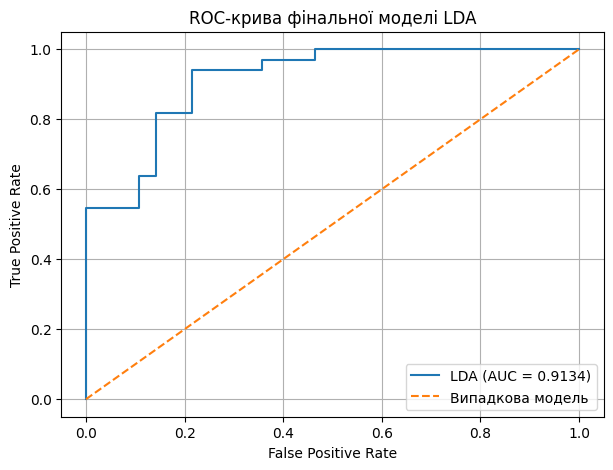

In [38]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label="LDA (AUC = 0.9134)")
plt.plot([0, 1], [0, 1], linestyle="--", label="Випадкова модель")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-крива фінальної моделі LDA")
plt.legend()
plt.grid()
plt.show()

## 8. Матриця помилок фінальної моделі

Матриця помилок показує кількість правильних і неправильних прогнозів моделі LDA на тестовій вибірці.

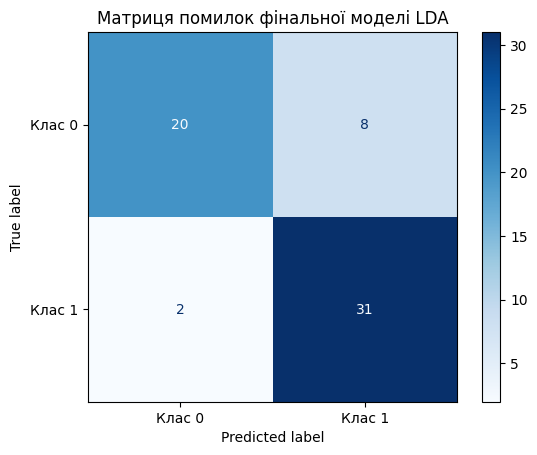

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

final_cm = confusion_matrix(y_test, test_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Клас 0", "Клас 1"]
)

display.plot(cmap="Blues")
plt.title("Матриця помилок фінальної моделі LDA")
plt.show()

## 9. Аналіз помилково класифікованих об'єктів

Визначаємо об'єкти тестової вибірки, для яких прогноз моделі не збігся з фактичним класом. Аналіз виконується без зміни параметрів фінальної моделі.

In [42]:
misclassified = X_test.copy()

misclassified["Фактичний клас"] = y_test
misclassified["Прогноз моделі"] = test_predictions
misclassified["Ймовірність класу 1"] = test_probabilities

misclassified = misclassified[
    misclassified["Фактичний клас"] != misclassified["Прогноз моделі"]
]

print("Кількість помилково класифікованих об'єктів:", len(misclassified))
from IPython.display import display as show_table
show_table(misclassified)

Кількість помилково класифікованих об'єктів: 10


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,Фактичний клас,Прогноз моделі,Ймовірність класу 1
194,60,140,185,155,3.0,1,2,0,0,0,1,0,2,0,1,0.927620
228,59,170,288,159,0.2,1,3,0,0,0,1,0,3,0,1,0.586925
95,53,142,226,111,0.0,1,0,0,0,1,2,0,3,1,0,0.121860
267,49,118,149,126,0.8,1,2,0,0,0,2,3,2,0,1,0.939342
302,57,130,236,174,0.0,0,1,0,0,0,1,1,2,0,1,0.875413
85,67,115,564,160,1.6,0,2,0,0,0,1,0,3,1,0,0.298441
272,67,120,237,71,1.0,1,0,0,1,0,1,0,2,0,1,0.613475
293,67,152,212,150,0.8,1,2,0,0,0,1,0,3,0,1,0.663495
286,59,134,204,162,0.8,1,3,0,1,0,2,2,2,0,1,0.956676
271,61,134,234,145,2.6,1,3,0,1,0,1,2,2,0,1,0.660384


## 10. Збереження фінальних результатів

Фінальні метрики моделі зберігаються у CSV-файл для подальшого використання та порівняння.

In [43]:
os.makedirs("reports", exist_ok=True)

final_test_metrics.to_csv(
    "reports/final_test_metrics.csv",
    index=False
)

print("Фінальні метрики збережено у reports/final_test_metrics.csv")

Фінальні метрики збережено у reports/final_test_metrics.csv


## 11. Збереження фінальної моделі

Навчену модель LDA зберігаємо у форматі JOBLIB разом із конвеєром попередньої обробки даних.

In [44]:
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/best_classifier.joblib")

print("Фінальну модель збережено у models/best_classifier.joblib")

Фінальну модель збережено у models/best_classifier.joblib


## 12. Перевірка збереженої моделі

Завантажуємо збережену модель та перевіряємо її роботу на трьох об'єктах тестової вибірки без ручної попередньої обробки даних.

In [45]:
loaded_model = joblib.load("models/best_classifier.joblib")

sample_predictions = loaded_model.predict(X_test.head(3))

print("Прогнози завантаженої моделі:", sample_predictions)
print("Кількість отриманих прогнозів:", len(sample_predictions))

Прогнози завантаженої моделі: [0 0 0]
Кількість отриманих прогнозів: 3


## 13. Висновок

У ході практичної роботи було проведено фінальне порівняння моделей класифікації за результатами п'ятикратної стратифікованої крос-валідації. Для остаточного оцінювання було обрано модель Linear Discriminant Analysis (LDA).

На тестовій вибірці модель отримала такі результати:
- Accuracy: 0.8361;
- Precision: 0.7949;
- Recall: 0.9394;
- F1-score: 0.8611;
- ROC AUC: 0.9134.

Було побудовано ROC-криву та матрицю помилок, а також проаналізовано 10 неправильно класифікованих об'єктів. Фінальну модель і результати оцінювання збережено у відповідних файлах. Додатково перевірено завантаження моделі та отримання прогнозів без ручної попередньої обробки даних.

Таким чином, усі основні етапи порівняння, вибору, оцінювання та збереження фінальної моделі класифікації виконано.